Libraries

In [1]:
import torch
import torchvision
from torch import nn
from torch.utils.data import random_split, DataLoader

torch.manual_seed(47)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


Data

In [2]:
train_val_set = torchvision.datasets.MNIST(
    root='./data',
    download=True,
    train=True,
    transform=torchvision.transforms.Compose([
        torchvision.transforms.ToTensor(),
        torchvision.transforms.Pad(2)
    ])
)

train_len = int(0.9 * len(train_val_set))
val_len = int(0.1 * len(train_val_set))
train_set, val_set = random_split(
    train_val_set,
    [train_len, val_len],
    generator=torch.Generator().manual_seed(47)
)

train_loader = DataLoader(
    dataset=train_set,
    batch_size = 128,
    shuffle=True
)

val_loader = DataLoader(
    dataset=val_set,
    batch_size = 128,
    shuffle=True
)

#------

test_set = torchvision.datasets.MNIST(
    root='./data',
    download=True,
    train=False,
    transform=torchvision.transforms.Compose([
        torchvision.transforms.ToTensor(),
        torchvision.transforms.Pad(2),
    ])
)

test_loader = DataLoader(
    dataset=test_set,
    batch_size = 128
)

100%|██████████| 9.91M/9.91M [00:00<00:00, 17.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 478kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.41MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.5MB/s]


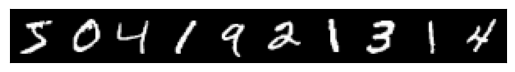

In [3]:
# sphinx_gallery_thumbnail_path = "../../gallery/assets/visualization_utils_thumbnail.png"

import torch
import numpy as np
import matplotlib.pyplot as plt

import torchvision.transforms.functional as F

plt.rcParams["savefig.bbox"] = 'tight'

def show(imgs):
    if not isinstance(imgs, list):
        imgs = [imgs]
    fix, axs = plt.subplots(ncols=len(imgs), squeeze=False)
    for i, img in enumerate(imgs):
        img = img.detach()
        img = F.to_pil_image(img)
        axs[0, i].imshow(np.asarray(img))
        axs[0, i].set(xticklabels=[], yticklabels=[], xticks=[], yticks=[])

grid = torchvision.utils.make_grid(train_val_set.data[:10].unsqueeze(dim=1), nrow=10)
show(grid)

Model

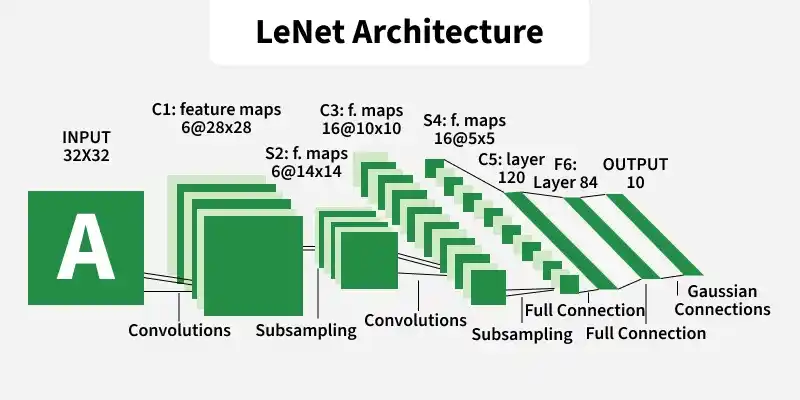

In [4]:
class LeNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.C1 = nn.Conv2d(in_channels=1, out_channels=6, kernel_size=5, stride=1)
        self.S2 = nn.AvgPool2d(kernel_size=2, stride=2)
        self.C3 = nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5, stride=1)
        self.S4 = nn.AvgPool2d(kernel_size=2, stride=2)
        self.C5 = nn.Conv2d(in_channels=16, out_channels=120, kernel_size=5, stride = 1)
        self.F6 = nn.Linear(in_features=120, out_features=84)
        self.out = nn.Linear(in_features=84, out_features=10)

    def forward(self, x):
        x = self.C1(x)
        x = torch.tanh(x)
        x = self.S2(x)
        x = self.C3(x)
        x = torch.tanh(x)
        x = self.S4(x)
        x = self.C5(x)
        x = torch.tanh(x)

        x = torch.flatten(x, start_dim=1)

        x = self.F6(x)
        x = torch.tanh(x)
        x = self.out(x)
        return x

Training loop

In [5]:
def train(model, loader, criterion, optimizer):
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for X, y in loader:
        X = X.to(device)
        y = y.to(device)

        optimizer.zero_grad()

        logits = model(X)
        loss = criterion(logits, y)

        loss.backward()
        optimizer.step()

        pred = logits.argmax(dim=1)
        batch_size = y.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (pred == y).sum().item()
        total_examples += batch_size

    average_loss = total_loss / total_examples
    accuracy = total_correct / total_examples

    return average_loss, accuracy

def evaluate(model, loader, criterion):
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    with torch.no_grad():
        for X, y in loader:
            X = X.to(device)
            y = y.to(device)
            
            logits = model(X)
            loss = criterion(logits, y)

            pred = logits.argmax(dim=1)
            batch_size = y.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (pred == y).sum().item()
            total_examples += batch_size

    average_loss = total_loss / total_examples
    accuracy = total_correct / total_examples

    return average_loss, accuracy

In [6]:
from torch.utils.tensorboard import SummaryWriter

writer = SummaryWriter("runs/lenet_mnist")

#------

from pathlib import Path

checkpoint_dir = Path("checkpoints")
checkpoint_dir.mkdir(exist_ok=True)

best_path = checkpoint_dir / "lenet_best.pt"
last_path = checkpoint_dir / "lenet_last.pt"

#------

lr = 0.01
n_epochs = 100
model = LeNet()
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

if device != torch.device('cpu'):
    model.to(device)

best_val_loss = 1e18
best_epoch = -1

for epoch in range(n_epochs):
    train_loss, train_accuracy = train(model, train_loader, criterion, optimizer)
    val_loss, val_accuracy = evaluate(model, val_loader, criterion)

    writer.add_scalar("Loss/train", train_loss, epoch)
    writer.add_scalar("Loss/validation", val_loss, epoch)
    writer.add_scalar("Accuracy/train", train_accuracy, epoch)
    writer.add_scalar("Accuracy/validation", val_accuracy, epoch)

    improved = bool(val_loss < best_val_loss)
    if improved:
        best_val_loss = val_loss
        best_epoch = epoch

    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch,
    }

    torch.save(checkpoint, last_path)
    if improved:
        torch.save(checkpoint, best_path)

    print(
        f"Epoch {epoch + 1:03d} | "
        f"train loss {train_loss:.4f} | "
        f"val loss {val_loss:.4f} | "
        f"train acc {train_accuracy:.2%} | "
        f"val acc {val_accuracy:.2%}"
    )

writer.close()

Epoch 001 | train loss 2.2316 | val loss 2.0514 | train acc 34.51% | val acc 47.57%
Epoch 002 | train loss 1.5283 | val loss 1.0037 | train acc 59.64% | val acc 74.28%
Epoch 003 | train loss 0.7804 | val loss 0.6248 | train acc 79.56% | val acc 83.28%
Epoch 004 | train loss 0.5483 | val loss 0.4890 | train acc 85.09% | val acc 86.23%
Epoch 005 | train loss 0.4454 | val loss 0.4157 | train acc 87.76% | val acc 88.60%
Epoch 006 | train loss 0.3854 | val loss 0.3686 | train acc 89.27% | val acc 89.77%
Epoch 007 | train loss 0.3451 | val loss 0.3369 | train acc 90.23% | val acc 90.60%
Epoch 008 | train loss 0.3148 | val loss 0.3096 | train acc 90.91% | val acc 91.17%
Epoch 009 | train loss 0.2898 | val loss 0.2872 | train acc 91.57% | val acc 91.75%
Epoch 010 | train loss 0.2682 | val loss 0.2678 | train acc 92.17% | val acc 92.25%
Epoch 011 | train loss 0.2491 | val loss 0.2506 | train acc 92.70% | val acc 92.70%
Epoch 012 | train loss 0.2319 | val loss 0.2342 | train acc 93.16% | val acc

Test

In [7]:
best_checkpoint = torch.load(best_path, map_location=device, weights_only=True)

model.load_state_dict(best_checkpoint["model_state_dict"])

test_loss, test_accuracy = evaluate(model, test_loader, criterion)

print("Best epoch:", best_checkpoint["best_epoch"] + 1)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

Best epoch: 100
Test loss: 0.0353
Test accuracy: 98.77%
